# Exploring the data (EDA)

What this notebook answers:
1. How much data do we have, and from when?
2. How many posts state a salary? What do salaries look like?
3. How balanced are the levels?
4. **Trap from the brief:** are posts that show a salary different from posts that hide it?

**Only the TRAIN part is used here.** The test posts (from `TEST_START`) stay unseen until release.

Run from the project folder: `jupyter notebook notebooks/eda.ipynb` (or *Run all*).

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":   # run from the project root
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from jobtracker.config import TEST_START
from jobtracker.data import load_vacancies
from jobtracker.db import connect

conn = connect()
all_rows = load_vacancies(conn)                       # unique IT job posts, with a split column
df = all_rows[all_rows["split"] == "train"].copy()    # <- train only
print(f"IT vacancies: {len(all_rows)} total, {len(df)} train (test from {TEST_START} is not used here)")

Matplotlib is building the font cache; this may take a moment.


IT vacancies: 3677 total, 3401 train (test from 2026-09-01 is not used here)


## 1. How much data, and from when?

collected posts (before the test period): 5998
channel
uzdev_jobs        2895
click_jobs        1452
it_jobs_uz         653
uzpythonjobs       652
UstozShogird       337
itvakansiyalar       9


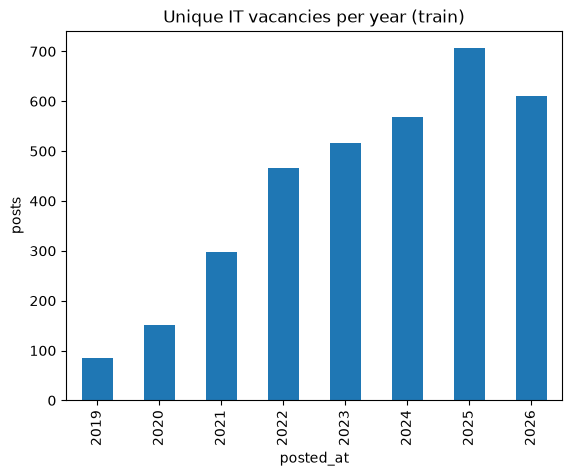

In [2]:
raw = pd.read_sql("SELECT channel, posted_at FROM raw_posts WHERE posted_at < ?", conn, params=(TEST_START,))
print("collected posts (before the test period):", len(raw))
print(raw["channel"].value_counts().to_string())

per_year = df["posted_at"].dt.year.value_counts().sort_index()
per_year.plot(kind="bar", title="Unique IT vacancies per year (train)", ylabel="posts")
plt.show()

In [3]:
# what the LLM said about all extracted posts (train period): how many are real IT jobs?
kinds = pd.read_sql(
    """SELECT v.is_job_post, v.is_it_job FROM vacancies v JOIN raw_posts r ON r.id = v.raw_id
       WHERE r.posted_at < ?""", conn, params=(TEST_START,))
kinds.value_counts().rename("posts")

is_job_post  is_it_job
1            1            3401
             0            1102
0            0             182
             1              99
Name: posts, dtype: int64

## 2. Salaries

posts with a salary: 3157 of 3401 (93%)
count    3157.0
mean     1234.0
std       985.0
min       100.0
25%       560.0
50%       960.0
75%      1500.0
max      9000.0


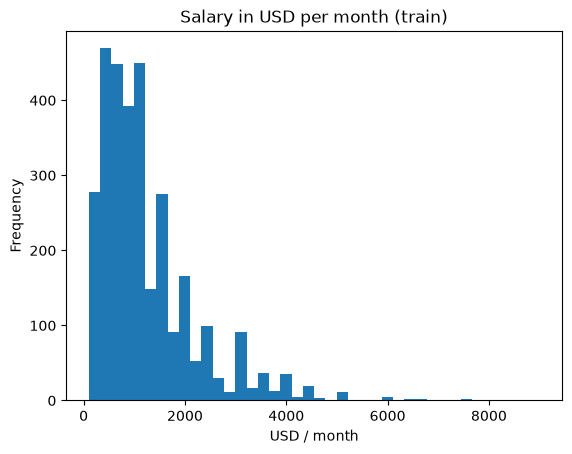

In [4]:
has_salary = df["salary_usd"].notna()
print(f"posts with a salary: {has_salary.sum()} of {len(df)} ({has_salary.mean():.0%})")
print(df["salary_usd"].describe().round(0).to_string())

df["salary_usd"].plot(kind="hist", bins=40, title="Salary in USD per month (train)")
plt.xlabel("USD / month")
plt.show()

## 3. Level balance

level
middle     1483
unknown     811
senior      726
junior      381


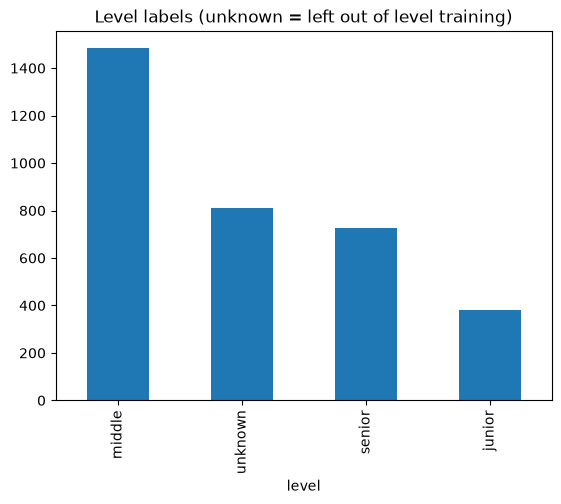

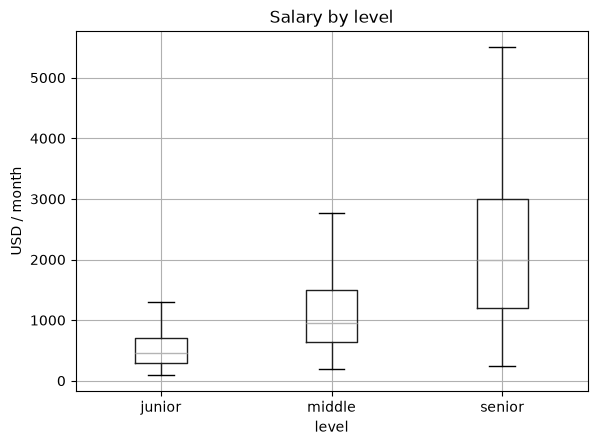

In [5]:
levels = df["level"].fillna("unknown").value_counts()
print(levels.to_string())
levels.plot(kind="bar", title="Level labels (unknown = left out of level training)")
plt.show()

df.dropna(subset=["level", "salary_usd"]).boxplot(column="salary_usd", by="level", showfliers=False)
plt.title("Salary by level"); plt.suptitle(""); plt.ylabel("USD / month")
plt.show()

## 4. Trap: posts with a salary vs posts without

The salary model only learns from posts that show a salary. If those posts are different
(other levels, other channels, other roles), the model may be biased for the rest.

In [6]:
df["shows_salary"] = has_salary
compare = pd.DataFrame({
    "share of posts": df["shows_salary"].value_counts(normalize=True),
    "median text length": df.groupby("shows_salary")["text"].apply(lambda t: t.str.len().median()),
}).round(2)
compare

,share of posts,median text length
shows_salary,,
False,0.07,861.0
True,0.93,990.0


In [7]:
# level mix in each group (rows sum to 1)
pd.crosstab(df["shows_salary"], df["level"].fillna("unknown"), normalize="index").round(2)

level,junior,middle,senior,unknown
shows_salary,,,,
False,0.40,0.25,0.08,0.26
True,0.09,0.45,0.22,0.24


In [8]:
# which channels hide the salary most often?
pd.crosstab(df["channel"], df["shows_salary"], normalize="index").round(2)

shows_salary,False,True
channel,,
UstozShogird,0.06,0.94
click_jobs,0.11,0.89
it_jobs_uz,0.17,0.83
itvakansiyalar,1.00,0.00
uzdev_jobs,0.03,0.97
uzpythonjobs,0.12,0.88


In [9]:
# top skills in each group
def top_skills(rows, n=10):
    return Counter(s for row in rows["skills"] for s in json.loads(row or "[]")).most_common(n)

print("with salary:   ", top_skills(df[df["shows_salary"]]))
print("without salary:", top_skills(df[~df["shows_salary"]]))

with salary:    [('Git', 1018), ('Python', 790), ('PostgreSQL', 780), ('JavaScript', 688), ('Docker', 550), ('SQL', 445), ('React', 427), ('Django', 414), ('CSS', 387), ('REST API', 380)]
without salary: [('Python', 73), ('JavaScript', 51), ('Git', 46), ('PostgreSQL', 40), ('React', 34), ('CSS', 33), ('HTML', 30), ('Django', 27), ('SQL', 24), ('Node.js', 22)]


## Findings (train part, 2026-11-19)

- **Rows:** 3,401 unique IT vacancies for training; 2,590 have a known level and 3,157 (93%) state a salary.
  Of all extracted posts, about 1 in 4 is not an IT job (mostly from the click_jobs aggregator) and is left out.
- **Salaries** are right-skewed: median about \$960, middle 50% between \$560 and \$1,500, a few up to \$9,000.
  MAE will be driven by the high-salary tail.
- **Levels** are unbalanced: middle 1,483, senior 726, junior 381 (811 unknown and excluded). That is why
  we use macro F1 and not accuracy.
- **Bias trap:** posts that hide the salary are very different. 40% of them are junior, compared with 9% of posts
  that show a salary. So the salary model sees few junior posts and will likely **overestimate junior
  salaries**, which is the costly mistake for students. We report error per level and the share of
  over-estimates (>30%) next to MAE.
- Hiding the salary is rare in uzdev_jobs (3%) and more common in it_jobs_uz (17%), so the channel mix matters too.
